# RQ17 — Paired bootstrap uncertainty for the principal generalization claims

## Scientific question

**Which of the principal effects identified in RQ1–RQ16 remain directionally resolved after finite-test-set uncertainty is propagated from the frozen outer-test predictions?**

RQ17 is not a new benchmark and does not retrain any model.

The uncertainty object is the **finite outer test set**. Following the frozen methodological contract:

- predictions remain fixed;
- no repeated-training seed experiment is introduced;
- 1,000 bootstrap replicates are used by default;
- supervised resampling is stratified by true class;
- PU resampling is stratified by observed role (`P` / `U`);
- paired comparisons use the same resampled entities/weights for both models;
- percentile 95% confidence intervals are reported.

The intervals therefore describe:

> **finite-test-set uncertainty conditional on the fitted models and the frozen experimental design.**

They do **not** estimate training-seed uncertainty.


## Why RQ17 is targeted rather than exhaustive

The factorial benchmark contains thousands of possible contrasts. Bootstrapping all pairwise combinations would create a massive inferential layer with little additional scientific value.

RQ17 instead targets claims that already survived the descriptive and sensitivity analyses:

### Supervised representation claims

1. `ESM2-T30 − ESM2-T6`
2. `ESM2-T30 − Roxy`

evaluated at four informative R/S corners:

- R90/S90
- R90/S30
- R30/S90
- R30/S30

for every biological task and downstream learner.

### Supervised algorithm claims

Within ESM2-T30:

3. `MLP − LR`
4. `MLP − XGB`

at the same four corners.

These test whether the large representation effect and the smaller downstream-algorithm effect remain distinguishable after paired finite-test uncertainty.

### Common-test generalization claims

5. `S30 − S90` on **pairwise common proteins**, at each fixed R, for all supervised tasks/representations/algorithms.

This directly bootstraps the RQ16 result that the S penalty collapses as R becomes stringent.

6. `R30 − R90` on pairwise common proteins as a **secondary sensitivity analysis**, restricted to ESM2-T30 because RQ16 showed that native R effects strongly mix evidence/population restructuring with same-entity difficulty.

### PU claims

7. `BaggingPU − naive` for U95 recovery.
8. `Elkan–Noto − naive` for U95 recovery.
9. `ESM2-T30 − ESM2-T6` within each PU paradigm for U95 recovery.

These are paired because the same frozen P/U outer-test entities are evaluated inside each matched PU cell.

### Low-N uncertainty

10. VAL receives an explicit single-model finite-test uncertainty audit under ESM2-T30 at the four corners, always reporting positive support.


## Interpretation contract

RQ17 reports **effect sizes and uncertainty**, not a multiple-testing leaderboard.

For a paired delta:

\[
\Delta = M_B - M_A
\]

we report:

- observed point delta;
- bootstrap mean and median;
- 2.5th and 97.5th percentiles;
- bootstrap CI width;
- \(P(\Delta>0)\);
- \(P(\Delta<0)\);
- whether the 95% interval lies entirely above zero, entirely below zero, or overlaps zero.

Terminology:

- **directionally resolved positive**: CI lower bound > 0;
- **directionally resolved negative**: CI upper bound < 0;
- **uncertain / overlaps zero**: otherwise.

No bootstrap p-values are created.

A confidence interval overlapping zero is not evidence of equivalence.

For VAL, wide or discrete intervals are interpreted as a consequence of limited finite-test support, not as instability of model training.


## Runtime / reproducibility contract

This notebook is intentionally heavier than earlier descriptive workbenches.

To avoid losing work:

- every bootstrap family uses a deterministic contrast-specific seed;
- results are checkpointed incrementally to TSV;
- rerunning the notebook skips completed contrasts;
- default bootstrap count is `1000`;
- the default batch size is conservative to avoid large memory spikes;
- environment variables can change runtime parameters for debugging, but manuscript results must use the default 1,000 replicates.

Before the benchmark is touched, a synthetic **bootstrap-engine self-test** must pass for:

- binary supervised paired metrics;
- multiclass paired metrics;
- PU U95 paired recovery;
- single-model VAL uncertainty.


In [1]:
from pathlib import Path
from functools import lru_cache
import hashlib
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 280)
pd.set_option("display.max_rows", 500)

N_BOOT = int(os.environ.get("RQ17_BOOTSTRAPS", "1000"))
BOOT_BATCH = int(os.environ.get("RQ17_BOOT_BATCH", "32"))
BASE_SEED = 42
CHECKPOINT_EVERY = int(os.environ.get("RQ17_CHECKPOINT_EVERY", "10"))

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]
CORNERS = [(90, 90), (90, 30), (30, 90), (30, 30)]

TASK_PATHS = {
    "global_easy": "global_easy",
    "global_hard": "global_hard",
    "global_mixed": "global_mixed",
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

MULTICLASS_TASKS = ["multiclass_clean"]

REP_T30 = "esm2_t30_150m"
REP_T6 = "esm2_t6_8m"
REP_ROXY = "roxy_48"

PU_TASKS = ["pu_conservative", "pu_broad"]
PU_METHODS = ["naive", "baggingpu", "elkan_noto"]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/training_supervised").is_dir()
            and (candidate / "results/analysis_pu/stage12a_qc").is_dir()
            and (candidate / "results/analysis_pu/stage12b2").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the PhageLysClass project root containing "
        "supervised Stage12A/training outputs and PU Stage12 outputs."
    )

ROOT = find_project_root()

SUP_STAGE12A = ROOT / "results/analysis_supervised/stage12a"
SUP_TRAINING = ROOT / "results/training_supervised"
SUP_CACHE = ROOT / "results/analysis_supervised/notebook_cache"

PU_STAGE12B2 = ROOT / "results/analysis_pu/stage12b2"
PU_QC = ROOT / "results/analysis_pu/stage12a_qc"
PU_CACHE = ROOT / "results/analysis_pu/notebook_cache"

RQ17_CACHE = ROOT / "results/analysis_bootstrap/rq17"
RQ17_CACHE.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("N_BOOT:", N_BOOT)
print("BOOT_BATCH:", BOOT_BATCH)
print("RQ17_CACHE:", RQ17_CACHE)


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
N_BOOT: 1000
BOOT_BATCH: 32
RQ17_CACHE: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_bootstrap/rq17


# 1. Load frozen registries and validate benchmark coverage


In [2]:
supervised_master = pd.read_csv(
    SUP_STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

required_sup = {
    "task", "R", "S", "representation", "algorithm",
}
missing = required_sup - set(supervised_master.columns)
if missing:
    raise KeyError(
        f"Supervised master missing columns: {sorted(missing)}"
    )

SUP_TASKS = sorted(supervised_master["task"].unique())
SUP_REPS = sorted(supervised_master["representation"].unique())
SUP_ALGORITHMS = sorted(supervised_master["algorithm"].unique())

assert set(SUP_TASKS) == set(TASK_PATHS)
assert REP_T30 in SUP_REPS
assert REP_T6 in SUP_REPS
assert REP_ROXY in SUP_REPS

sup_cov = (
    supervised_master.groupby(
        ["task", "R", "S", "representation", "algorithm"]
    )
    .size()
)
assert len(sup_cov) == len(supervised_master)
assert sup_cov.eq(1).all()

pu_registry = pd.read_csv(
    PU_QC / "pu_completed_registry.tsv",
    sep="\t",
    low_memory=False,
)

required_pu = {
    "experiment_id", "task", "R", "S",
    "representation", "method", "algorithm", "path",
}
missing = required_pu - set(pu_registry.columns)
if missing:
    raise KeyError(
        f"PU registry missing columns: {sorted(missing)}"
    )

assert len(pu_registry) == 768
assert set(pu_registry["task"]) == set(PU_TASKS)
assert set(pu_registry["method"]) == set(PU_METHODS)

PU_REPS = sorted(pu_registry["representation"].unique())
PU_ALGORITHMS = sorted(pu_registry["algorithm"].unique())

assert REP_T30 in PU_REPS
assert REP_T6 in PU_REPS

print("Supervised rows:", len(supervised_master))
print("Supervised algorithms:", SUP_ALGORITHMS)
print("PU rows:", len(pu_registry))
print("PU algorithms:", PU_ALGORITHMS)


Supervised rows: 2240
Supervised algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']
PU rows: 768
PU algorithms: ['LR', 'XGB']


# 2. Identity, alignment, and metric utilities


In [3]:
def stable_seed(*parts):
    text = "||".join(map(str, (BASE_SEED, *parts)))
    h = hashlib.sha256(text.encode("utf-8")).hexdigest()
    return int(h[:8], 16)

def _clean_text(series):
    return (
        series.astype("string")
        .fillna("")
        .str.strip()
        .astype(str)
    )

def attach_sequence_key(df):
    out = df.copy()

    for c in ["sequence_sha256", "sequence_uid", "entity_id"]:
        if c in out.columns:
            key = _clean_text(out[c])
            if key.ne("").all() and not key.duplicated().any():
                if c == "sequence_sha256":
                    key = key.str.lower()
                out["sequence_key"] = key
                out["sequence_key_source"] = c
                return out

    for c in ["sequence", "sequence_norm", "seq"]:
        if c in out.columns:
            seq = (
                _clean_text(out[c])
                .str.replace(r"\s+", "", regex=True)
                .str.upper()
            )
            if seq.ne("").all():
                key = seq.map(
                    lambda x: hashlib.sha256(
                        x.encode("utf-8")
                    ).hexdigest()
                )
                if not key.duplicated().any():
                    out["sequence_key"] = key
                    out["sequence_key_source"] = "derived_sequence_sha256"
                    return out

    raise RuntimeError(
        "Could not construct a unique sequence key. "
        f"Columns: {list(out.columns)}"
    )

def normalize_binary(values):
    s = pd.Series(values)

    numeric = pd.to_numeric(s, errors="coerce")
    if numeric.notna().all():
        vals = numeric.astype(int)
        if set(vals.unique()) <= {0, 1}:
            return vals.to_numpy()

    mapping = {
        "false": 0,
        "true": 1,
        "negative": 0,
        "positive": 1,
        "n": 0,
        "p": 1,
        "0": 0,
        "1": 1,
    }

    mapped = _clean_text(s).str.lower().map(mapping)
    if mapped.notna().all():
        return mapped.astype(int).to_numpy()

    raise ValueError(
        f"Could not normalize binary labels: "
        f"{sorted(s.astype(str).unique())[:20]}"
    )

def detect_score_col(df):
    for c in [
        "score_positive",
        "score",
        "probability",
        "proba_positive",
        "corrected_score",
    ]:
        if c in df.columns:
            return c
    return None

def task_type(task):
    return "binary" if task in BINARY_TASKS else "multiclass"

def align_frames(df_a, df_b, require_full=True):
    a = attach_sequence_key(df_a)
    b = attach_sequence_key(df_b)

    keep_a = [
        c for c in a.columns
        if c not in {"sequence_key_source"}
    ]
    keep_b = [
        c for c in b.columns
        if c not in {"sequence_key_source"}
    ]

    a = a[keep_a].copy()
    b = b[keep_b].copy()

    ids_a = set(a["sequence_key"].astype(str))
    ids_b = set(b["sequence_key"].astype(str))
    shared = ids_a & ids_b

    if require_full and (shared != ids_a or shared != ids_b):
        raise RuntimeError(
            "Paired comparison expected identical test identities but "
            f"found nA={len(ids_a)}, nB={len(ids_b)}, shared={len(shared)}."
        )

    a = (
        a[a["sequence_key"].isin(shared)]
        .sort_values("sequence_key")
        .reset_index(drop=True)
    )
    b = (
        b[b["sequence_key"].isin(shared)]
        .sort_values("sequence_key")
        .reset_index(drop=True)
    )

    if not a["sequence_key"].equals(b["sequence_key"]):
        raise RuntimeError("Sequence alignment failed.")

    return a, b

def assert_same_labels(a, b, label_col="y_true"):
    if label_col not in a.columns or label_col not in b.columns:
        raise KeyError(f"Missing {label_col}")

    va = a[label_col].astype(str).to_numpy()
    vb = b[label_col].astype(str).to_numpy()

    if not np.array_equal(va, vb):
        raise RuntimeError(
            f"{label_col} differs for aligned exact-sequence entities."
        )

def summarize_bootstrap(delta, point_delta, extra=None):
    delta = np.asarray(delta, dtype=float)
    delta = delta[np.isfinite(delta)]

    if len(delta) == 0:
        result = {
            "n_boot_valid": 0,
            "point_delta": point_delta,
            "boot_mean": np.nan,
            "boot_median": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "ci_width": np.nan,
            "p_delta_gt_0": np.nan,
            "p_delta_lt_0": np.nan,
            "directional_consistency": np.nan,
            "ci_relation": "not_estimable",
        }
    else:
        lo, hi = np.quantile(delta, [0.025, 0.975])

        if lo > 0:
            relation = "positive"
        elif hi < 0:
            relation = "negative"
        else:
            relation = "overlaps_zero"

        p_pos = float(np.mean(delta > 0))
        p_neg = float(np.mean(delta < 0))

        result = {
            "n_boot_valid": len(delta),
            "point_delta": float(point_delta),
            "boot_mean": float(np.mean(delta)),
            "boot_median": float(np.median(delta)),
            "ci_low": float(lo),
            "ci_high": float(hi),
            "ci_width": float(hi - lo),
            "p_delta_gt_0": p_pos,
            "p_delta_lt_0": p_neg,
            "directional_consistency": max(p_pos, p_neg),
            "ci_relation": relation,
        }

    if extra:
        result.update(extra)

    return result


# 3. Fast class-stratified weighted-bootstrap engines


In [4]:
def _binary_confusion_from_weights(y, pred, W):
    y = np.asarray(y, dtype=int)
    pred = np.asarray(pred, dtype=int)
    W = np.asarray(W)

    pos = y == 1
    neg = ~pos

    tp = W[:, pos] @ pred[pos].astype(float)
    fp = W[:, neg] @ pred[neg].astype(float)

    n_pos = W[:, pos].sum(axis=1)
    n_neg = W[:, neg].sum(axis=1)

    fn = n_pos - tp
    tn = n_neg - fp

    return tp, tn, fp, fn

def _mcc_from_confusion(tp, tn, fp, fn):
    num = tp * tn - fp * fn
    den = np.sqrt(
        (tp + fp)
        * (tp + fn)
        * (tn + fp)
        * (tn + fn)
    )

    out = np.full_like(num, np.nan, dtype=float)
    valid = den > 0
    out[valid] = num[valid] / den[valid]
    return out

def _balanced_accuracy_from_confusion(tp, tn, fp, fn):
    sens_den = tp + fn
    spec_den = tn + fp

    sens = np.divide(
        tp,
        sens_den,
        out=np.full_like(tp, np.nan, dtype=float),
        where=sens_den > 0,
    )
    spec = np.divide(
        tn,
        spec_den,
        out=np.full_like(tn, np.nan, dtype=float),
        where=spec_den > 0,
    )

    return (sens + spec) / 2.0

def _weighted_average_precision_batch(y, score, W):
    y = np.asarray(y, dtype=int)
    score = np.asarray(score, dtype=float)
    W = np.asarray(W)

    order = np.argsort(-score, kind="stable")
    score_s = score[order]
    y_s = y[order]
    W_s = W[:, order]

    if len(score_s) == 0:
        return np.full(W.shape[0], np.nan)

    starts = np.r_[
        0,
        np.flatnonzero(score_s[1:] != score_s[:-1]) + 1,
    ]

    total_group = np.add.reduceat(
        W_s,
        starts,
        axis=1,
    )
    pos_group = np.add.reduceat(
        W_s * y_s[None, :],
        starts,
        axis=1,
    )

    cum_total = np.cumsum(total_group, axis=1)
    cum_pos = np.cumsum(pos_group, axis=1)

    precision = np.divide(
        cum_pos,
        cum_total,
        out=np.zeros_like(cum_pos, dtype=float),
        where=cum_total > 0,
    )

    n_pos = pos_group.sum(axis=1)

    ap = np.divide(
        np.sum(precision * pos_group, axis=1),
        n_pos,
        out=np.full(W.shape[0], np.nan),
        where=n_pos > 0,
    )

    return ap

def _binary_point_metrics(y, pred, score=None):
    y = np.asarray(y, dtype=int)
    pred = np.asarray(pred, dtype=int)

    tp = float(np.sum((y == 1) & (pred == 1)))
    tn = float(np.sum((y == 0) & (pred == 0)))
    fp = float(np.sum((y == 0) & (pred == 1)))
    fn = float(np.sum((y == 1) & (pred == 0)))

    mcc = _mcc_from_confusion(
        np.array([tp]),
        np.array([tn]),
        np.array([fp]),
        np.array([fn]),
    )[0]

    ba = _balanced_accuracy_from_confusion(
        np.array([tp]),
        np.array([tn]),
        np.array([fp]),
        np.array([fn]),
    )[0]

    result = {
        "mcc": mcc,
        "balanced_accuracy": ba,
        "recall": (
            tp / (tp + fn)
            if (tp + fn) else np.nan
        ),
    }

    if score is not None:
        W = np.ones((1, len(y)), dtype=np.int32)
        ap = _weighted_average_precision_batch(
            y, score, W
        )[0]
        prev = float(np.mean(y == 1))
        result["ap_skill"] = (
            (ap - prev) / (1.0 - prev)
            if prev < 1.0
            else np.nan
        )

    return result

def _stratified_weight_batch_binary(y, batch_n, rng):
    y = np.asarray(y, dtype=int)
    pos_idx = np.flatnonzero(y == 1)
    neg_idx = np.flatnonzero(y == 0)

    if len(pos_idx) == 0 or len(neg_idx) == 0:
        raise ValueError(
            "Binary stratified bootstrap requires both classes."
        )

    W = np.zeros(
        (batch_n, len(y)),
        dtype=np.int32,
    )

    W[:, pos_idx] = rng.multinomial(
        len(pos_idx),
        np.full(len(pos_idx), 1.0 / len(pos_idx)),
        size=batch_n,
    )

    W[:, neg_idx] = rng.multinomial(
        len(neg_idx),
        np.full(len(neg_idx), 1.0 / len(neg_idx)),
        size=batch_n,
    )

    return W

def bootstrap_binary_pair(
    y,
    pred_a,
    pred_b,
    score_a=None,
    score_b=None,
    *,
    n_boot=N_BOOT,
    batch_size=BOOT_BATCH,
    seed=42,
    include_ap=True,
):
    y = np.asarray(y, dtype=int)
    pred_a = np.asarray(pred_a, dtype=int)
    pred_b = np.asarray(pred_b, dtype=int)

    if not (
        len(y) == len(pred_a) == len(pred_b)
    ):
        raise ValueError("Binary pair arrays have unequal lengths.")

    if include_ap and (
        score_a is None or score_b is None
    ):
        include_ap = False

    point_a = _binary_point_metrics(
        y, pred_a, score_a if include_ap else None
    )
    point_b = _binary_point_metrics(
        y, pred_b, score_b if include_ap else None
    )

    metrics = ["mcc", "balanced_accuracy"]
    if include_ap:
        metrics.append("ap_skill")

    deltas = {
        metric: []
        for metric in metrics
    }

    rng = np.random.default_rng(seed)

    done = 0
    while done < n_boot:
        b = min(batch_size, n_boot - done)
        W = _stratified_weight_batch_binary(
            y, b, rng
        )

        tp_a, tn_a, fp_a, fn_a = _binary_confusion_from_weights(
            y, pred_a, W
        )
        tp_b, tn_b, fp_b, fn_b = _binary_confusion_from_weights(
            y, pred_b, W
        )

        mcc_a = _mcc_from_confusion(
            tp_a, tn_a, fp_a, fn_a
        )
        mcc_b = _mcc_from_confusion(
            tp_b, tn_b, fp_b, fn_b
        )

        ba_a = _balanced_accuracy_from_confusion(
            tp_a, tn_a, fp_a, fn_a
        )
        ba_b = _balanced_accuracy_from_confusion(
            tp_b, tn_b, fp_b, fn_b
        )

        deltas["mcc"].extend(
            (mcc_b - mcc_a).tolist()
        )
        deltas["balanced_accuracy"].extend(
            (ba_b - ba_a).tolist()
        )

        if include_ap:
            ap_a = _weighted_average_precision_batch(
                y,
                np.asarray(score_a, dtype=float),
                W,
            )
            ap_b = _weighted_average_precision_batch(
                y,
                np.asarray(score_b, dtype=float),
                W,
            )

            prev = float(np.mean(y == 1))
            ap_skill_a = (
                (ap_a - prev) / (1.0 - prev)
            )
            ap_skill_b = (
                (ap_b - prev) / (1.0 - prev)
            )

            deltas["ap_skill"].extend(
                (ap_skill_b - ap_skill_a).tolist()
            )

        done += b

    summaries = {}
    for metric in metrics:
        summaries[metric] = summarize_bootstrap(
            deltas[metric],
            point_b[metric] - point_a[metric],
        )

    return summaries

def bootstrap_binary_single(
    y,
    pred,
    score=None,
    *,
    n_boot=N_BOOT,
    batch_size=BOOT_BATCH,
    seed=42,
):
    y = np.asarray(y, dtype=int)
    pred = np.asarray(pred, dtype=int)

    include_ap = score is not None
    point = _binary_point_metrics(
        y,
        pred,
        score if include_ap else None,
    )

    boot = {
        "mcc": [],
        "recall": [],
    }
    if include_ap:
        boot["ap_skill"] = []

    rng = np.random.default_rng(seed)
    done = 0

    while done < n_boot:
        b = min(batch_size, n_boot - done)
        W = _stratified_weight_batch_binary(
            y, b, rng
        )

        tp, tn, fp, fn = _binary_confusion_from_weights(
            y, pred, W
        )

        mcc = _mcc_from_confusion(
            tp, tn, fp, fn
        )
        recall = np.divide(
            tp,
            tp + fn,
            out=np.full_like(tp, np.nan, dtype=float),
            where=(tp + fn) > 0,
        )

        boot["mcc"].extend(mcc.tolist())
        boot["recall"].extend(recall.tolist())

        if include_ap:
            ap = _weighted_average_precision_batch(
                y,
                np.asarray(score, dtype=float),
                W,
            )
            prev = float(np.mean(y == 1))
            ap_skill = (
                (ap - prev) / (1.0 - prev)
            )
            boot["ap_skill"].extend(
                ap_skill.tolist()
            )

        done += b

    rows = {}
    for metric, values in boot.items():
        arr = np.asarray(values, dtype=float)
        arr = arr[np.isfinite(arr)]

        if len(arr):
            lo, hi = np.quantile(arr, [0.025, 0.975])
            rows[metric] = {
                "point_value": point[metric],
                "boot_mean": float(np.mean(arr)),
                "boot_median": float(np.median(arr)),
                "ci_low": float(lo),
                "ci_high": float(hi),
                "ci_width": float(hi - lo),
                "n_boot_valid": len(arr),
            }
        else:
            rows[metric] = {
                "point_value": point[metric],
                "boot_mean": np.nan,
                "boot_median": np.nan,
                "ci_low": np.nan,
                "ci_high": np.nan,
                "ci_width": np.nan,
                "n_boot_valid": 0,
            }

    return rows


In [5]:
def _multiclass_confusion_batch(
    y_true,
    y_pred,
    W,
    classes,
):
    y_true = np.asarray(y_true, dtype=str)
    y_pred = np.asarray(y_pred, dtype=str)
    classes = list(map(str, classes))

    mapping = {
        label: i
        for i, label in enumerate(classes)
    }

    y_idx = np.array(
        [mapping[x] for x in y_true],
        dtype=int,
    )
    p_idx = np.array(
        [mapping[x] for x in y_pred],
        dtype=int,
    )

    k = len(classes)
    code = y_idx * k + p_idx

    indicators = np.eye(
        k * k,
        dtype=np.int8,
    )[code]

    cm_flat = W @ indicators
    return cm_flat.reshape(
        W.shape[0], k, k
    )

def _multiclass_metrics_from_cm(cm):
    cm = np.asarray(cm, dtype=float)

    t = cm.sum(axis=2)
    p = cm.sum(axis=1)
    c = np.trace(cm, axis1=1, axis2=2)
    s = cm.sum(axis=(1, 2))

    num = c * s - np.sum(t * p, axis=1)

    den = np.sqrt(
        (
            s ** 2
            - np.sum(p ** 2, axis=1)
        )
        *
        (
            s ** 2
            - np.sum(t ** 2, axis=1)
        )
    )

    mcc = np.divide(
        num,
        den,
        out=np.full_like(num, np.nan, dtype=float),
        where=den > 0,
    )

    tp = np.diagonal(
        cm,
        axis1=1,
        axis2=2,
    )
    fp = p - tp
    fn = t - tp

    f1_den = 2 * tp + fp + fn
    f1 = np.divide(
        2 * tp,
        f1_den,
        out=np.zeros_like(tp, dtype=float),
        where=f1_den > 0,
    )
    macro_f1 = np.mean(f1, axis=1)

    recall = np.divide(
        tp,
        t,
        out=np.zeros_like(tp, dtype=float),
        where=t > 0,
    )
    balanced_accuracy = np.mean(
        recall,
        axis=1,
    )

    return {
        "mcc": mcc,
        "macro_f1": macro_f1,
        "balanced_accuracy": balanced_accuracy,
    }

def _stratified_weight_batch_multiclass(
    y,
    batch_n,
    rng,
):
    y = np.asarray(y, dtype=str)
    W = np.zeros(
        (batch_n, len(y)),
        dtype=np.int32,
    )

    for cls in sorted(np.unique(y)):
        idx = np.flatnonzero(y == cls)
        if len(idx) == 0:
            continue

        W[:, idx] = rng.multinomial(
            len(idx),
            np.full(
                len(idx),
                1.0 / len(idx),
            ),
            size=batch_n,
        )

    return W

def bootstrap_multiclass_pair(
    y,
    pred_a,
    pred_b,
    *,
    n_boot=N_BOOT,
    batch_size=BOOT_BATCH,
    seed=42,
):
    y = np.asarray(y, dtype=str)
    pred_a = np.asarray(pred_a, dtype=str)
    pred_b = np.asarray(pred_b, dtype=str)

    classes = sorted(
        set(y) | set(pred_a) | set(pred_b)
    )

    W1 = np.ones(
        (1, len(y)),
        dtype=np.int32,
    )

    point_a = _multiclass_metrics_from_cm(
        _multiclass_confusion_batch(
            y, pred_a, W1, classes
        )
    )
    point_b = _multiclass_metrics_from_cm(
        _multiclass_confusion_batch(
            y, pred_b, W1, classes
        )
    )

    metrics = [
        "mcc",
        "macro_f1",
        "balanced_accuracy",
    ]
    deltas = {
        metric: []
        for metric in metrics
    }

    rng = np.random.default_rng(seed)
    done = 0

    while done < n_boot:
        b = min(batch_size, n_boot - done)
        W = _stratified_weight_batch_multiclass(
            y, b, rng
        )

        ma = _multiclass_metrics_from_cm(
            _multiclass_confusion_batch(
                y, pred_a, W, classes
            )
        )
        mb = _multiclass_metrics_from_cm(
            _multiclass_confusion_batch(
                y, pred_b, W, classes
            )
        )

        for metric in metrics:
            deltas[metric].extend(
                (mb[metric] - ma[metric]).tolist()
            )

        done += b

    summaries = {}
    for metric in metrics:
        point_delta = (
            point_b[metric][0]
            - point_a[metric][0]
        )
        summaries[metric] = summarize_bootstrap(
            deltas[metric],
            point_delta,
        )

    return summaries


# 4. PU U95 bootstrap engine


In [6]:
def _weighted_order_statistic(
    score_sorted_asc,
    W_sorted,
    k,
):
    cum = np.cumsum(
        W_sorted,
        axis=1,
    )

    idx = np.argmax(
        cum > k,
        axis=1,
    )

    return score_sorted_asc[idx]

def _weighted_linear_quantile_batch(
    score,
    W,
    q,
):
    score = np.asarray(score, dtype=float)
    W = np.asarray(W)

    n = W.sum(axis=1)
    if not np.all(n == n[0]):
        raise RuntimeError(
            "Bootstrap replicate sizes differ."
        )

    n0 = int(n[0])
    if n0 == 0:
        return np.full(W.shape[0], np.nan)

    order = np.argsort(
        score,
        kind="stable",
    )
    score_s = score[order]
    W_s = W[:, order]

    h = (n0 - 1) * q
    k0 = int(np.floor(h))
    k1 = int(np.ceil(h))
    g = h - k0

    x0 = _weighted_order_statistic(
        score_s, W_s, k0
    )
    x1 = _weighted_order_statistic(
        score_s, W_s, k1
    )

    return (
        (1.0 - g) * x0
        + g * x1
    )

def _pu_point_u95(role, score):
    role = np.asarray(role, dtype=str)
    score = np.asarray(score, dtype=float)

    P = score[role == "P"]
    U = score[role == "U"]

    if len(P) == 0 or len(U) == 0:
        return np.nan

    q95 = np.quantile(U, 0.95)
    return float(np.mean(P >= q95))

def bootstrap_pu_u95_pair(
    role,
    score_a,
    score_b,
    *,
    n_boot=N_BOOT,
    batch_size=BOOT_BATCH,
    seed=42,
):
    role = np.asarray(role, dtype=str)
    score_a = np.asarray(score_a, dtype=float)
    score_b = np.asarray(score_b, dtype=float)

    p_idx = np.flatnonzero(role == "P")
    u_idx = np.flatnonzero(role == "U")

    if len(p_idx) == 0 or len(u_idx) == 0:
        raise ValueError(
            "PU bootstrap requires both P and U."
        )

    point_a = _pu_point_u95(
        role, score_a
    )
    point_b = _pu_point_u95(
        role, score_b
    )

    delta = []
    rng = np.random.default_rng(seed)

    done = 0
    while done < n_boot:
        b = min(batch_size, n_boot - done)

        WP = rng.multinomial(
            len(p_idx),
            np.full(
                len(p_idx),
                1.0 / len(p_idx),
            ),
            size=b,
        ).astype(np.int32)

        WU = rng.multinomial(
            len(u_idx),
            np.full(
                len(u_idx),
                1.0 / len(u_idx),
            ),
            size=b,
        ).astype(np.int32)

        q_a = _weighted_linear_quantile_batch(
            score_a[u_idx],
            WU,
            0.95,
        )
        q_b = _weighted_linear_quantile_batch(
            score_b[u_idx],
            WU,
            0.95,
        )

        rec_a = np.sum(
            WP
            * (
                score_a[p_idx][None, :]
                >= q_a[:, None]
            ),
            axis=1,
        ) / len(p_idx)

        rec_b = np.sum(
            WP
            * (
                score_b[p_idx][None, :]
                >= q_b[:, None]
            ),
            axis=1,
        ) / len(p_idx)

        delta.extend(
            (rec_b - rec_a).tolist()
        )
        done += b

    return summarize_bootstrap(
        delta,
        point_b - point_a,
        extra={
            "n_P": len(p_idx),
            "n_U": len(u_idx),
            "point_A": point_a,
            "point_B": point_b,
        },
    )


# 5. Mandatory synthetic self-test before expensive benchmark execution


In [7]:
def _self_test():
    # Binary
    rng = np.random.default_rng(1)
    y = np.r_[
        np.zeros(80, dtype=int),
        np.ones(20, dtype=int),
    ]

    score_a = rng.normal(
        y * 0.8,
        0.8,
    )
    score_b = score_a + y * 0.35

    pred_a = (score_a >= 0.5).astype(int)
    pred_b = (score_b >= 0.5).astype(int)

    b = bootstrap_binary_pair(
        y,
        pred_a,
        pred_b,
        score_a,
        score_b,
        n_boot=100,
        batch_size=16,
        seed=11,
    )

    assert set(b) == {
        "mcc",
        "balanced_accuracy",
        "ap_skill",
    }
    assert all(
        x["n_boot_valid"] == 100
        for x in b.values()
    )

    # Binary single
    s = bootstrap_binary_single(
        y,
        pred_b,
        score_b,
        n_boot=100,
        batch_size=16,
        seed=12,
    )
    assert set(s) == {
        "mcc",
        "recall",
        "ap_skill",
    }

    # Multiclass
    ym = np.array(
        ["A"] * 50
        + ["B"] * 30
        + ["C"] * 20
    )
    pa = ym.copy()
    pb = ym.copy()

    pa[::7] = "B"
    pb[::13] = "B"

    m = bootstrap_multiclass_pair(
        ym,
        pa,
        pb,
        n_boot=100,
        batch_size=16,
        seed=13,
    )
    assert set(m) == {
        "mcc",
        "macro_f1",
        "balanced_accuracy",
    }

    # PU
    role = np.array(
        ["P"] * 30
        + ["U"] * 120
    )
    pu_a = np.r_[
        rng.normal(0.75, 0.12, 30),
        rng.normal(0.35, 0.15, 120),
    ]
    pu_b = np.r_[
        rng.normal(0.80, 0.10, 30),
        rng.normal(0.34, 0.14, 120),
    ]

    p = bootstrap_pu_u95_pair(
        role,
        pu_a,
        pu_b,
        n_boot=100,
        batch_size=16,
        seed=14,
    )
    assert p["n_boot_valid"] == 100
    assert p["n_P"] == 30
    assert p["n_U"] == 120

    return {
        "binary_pair": b["mcc"],
        "binary_single": s["mcc"],
        "multiclass_pair": m["mcc"],
        "pu_pair": p,
    }

SELF_TEST = _self_test()

print("PASS — RQ17 bootstrap engine self-test.")
display(
    pd.DataFrame(
        {
            k: {
                kk: vv
                for kk, vv in v.items()
                if kk in {
                    "point_delta",
                    "ci_low",
                    "ci_high",
                    "n_boot_valid",
                    "point_value",
                }
            }
            for k, v in SELF_TEST.items()
        }
    ).T
)


PASS — RQ17 bootstrap engine self-test.


,n_boot_valid,point_delta,ci_low,ci_high,point_value
binary_pair,100.0,0.038813,0.000000,0.121139,NaN
binary_single,100.0,NaN,0.331300,0.701985,0.514496
multiclass_pair,100.0,0.084282,-0.013655,0.159757,NaN
pu_pair,100.0,0.100000,0.000000,0.266667,NaN


**Do not continue** if this cell fails.

It deliberately exercises the same code paths used later for the expensive benchmark, including weighted AP, multiclass confusion matrices, percentile intervals, and PU U95 threshold bootstrapping.


# 6. Frozen prediction loaders


In [8]:
def supervised_prediction_path(
    task,
    r,
    s,
    representation,
    algorithm,
):
    return (
        SUP_TRAINING
        / TASK_PATHS[task]
        / f"R{r}_S{s}"
        / representation
        / algorithm
        / "outer_test_predictions.parquet"
    )

@lru_cache(maxsize=48)
def load_supervised_prediction(
    task,
    r,
    s,
    representation,
    algorithm,
):
    p = supervised_prediction_path(
        task, r, s, representation, algorithm
    )

    if not p.is_file():
        raise FileNotFoundError(p)

    df = pd.read_parquet(p)
    df = attach_sequence_key(df)

    required = {
        "sequence_key",
        "y_true",
        "y_pred",
    }
    missing = required - set(df.columns)
    if missing:
        raise KeyError(
            f"{p}: missing {sorted(missing)}"
        )

    return df

pu_lookup = {
    (
        row.task,
        int(row.R),
        int(row.S),
        row.representation,
        row.method,
        row.algorithm,
    ): Path(row.path)
    for row in pu_registry.itertuples(index=False)
}

@lru_cache(maxsize=48)
def load_pu_scores(
    task,
    r,
    s,
    representation,
    method,
    algorithm,
):
    p = (
        pu_lookup[
            (
                task,
                int(r),
                int(s),
                representation,
                method,
                algorithm,
            )
        ]
        / "outer_test_scores.parquet"
    )

    if not p.is_file():
        raise FileNotFoundError(p)

    df = pd.read_parquet(p)
    df = attach_sequence_key(df)

    if "observed_role" not in df.columns:
        raise KeyError(
            f"{p}: missing observed_role"
        )

    score_col = detect_score_col(df)
    if score_col is None:
        raise KeyError(
            f"{p}: no usable PU score column"
        )

    df["score_for_rq17"] = pd.to_numeric(
        df[score_col],
        errors="coerce",
    )
    df["observed_role"] = (
        df["observed_role"]
        .astype(str)
        .str.upper()
    )

    if df["score_for_rq17"].isna().any():
        raise RuntimeError(
            f"{p}: non-numeric PU scores detected."
        )

    return df


# 7. Checkpoint runner


In [9]:
def _load_checkpoint(path):
    if path.is_file():
        return pd.read_csv(
            path,
            sep="\t",
            low_memory=False,
        )
    return pd.DataFrame()

def _save_checkpoint(frame, path):
    tmp = path.with_suffix(
        path.suffix + ".tmp"
    )
    frame.to_csv(
        tmp,
        sep="\t",
        index=False,
    )
    tmp.replace(path)

def run_specs_with_checkpoint(
    specs,
    checkpoint_path,
    worker,
    *,
    family_name,
):
    specs = pd.DataFrame(specs).copy()

    if "contrast_id" not in specs.columns:
        raise KeyError(
            f"{family_name}: specs require contrast_id."
        )

    existing = _load_checkpoint(
        checkpoint_path
    )

    completed = (
        set(existing["contrast_id"].astype(str))
        if len(existing)
        else set()
    )

    todo = specs[
        ~specs["contrast_id"]
        .astype(str)
        .isin(completed)
    ].copy()

    print(
        f"{family_name}: total={len(specs)}, "
        f"completed={len(completed)}, "
        f"remaining={len(todo)}"
    )

    frames = [existing] if len(existing) else []
    buffer = []

    for i, rec in enumerate(
        todo.to_dict("records"),
        start=1,
    ):
        result = worker(rec)
        buffer.append(
            pd.DataFrame(result)
        )

        if (
            i % CHECKPOINT_EVERY == 0
            or i == len(todo)
        ):
            if buffer:
                frames.extend(buffer)
                buffer = []

            merged = pd.concat(
                frames,
                ignore_index=True,
            )

            merged = (
                merged.sort_values(
                    ["contrast_id", "metric"],
                    kind="stable",
                )
                .drop_duplicates(
                    ["contrast_id", "metric"],
                    keep="last",
                )
                .reset_index(drop=True)
            )

            _save_checkpoint(
                merged,
                checkpoint_path,
            )

            frames = [merged]

            print(
                f"  {family_name}: "
                f"{i}/{len(todo)} new contrasts completed"
            )

    final = (
        pd.concat(frames, ignore_index=True)
        if frames
        else existing
    )

    if len(final):
        final = (
            final.sort_values(
                ["contrast_id", "metric"],
                kind="stable",
            )
            .drop_duplicates(
                ["contrast_id", "metric"],
                keep="last",
            )
            .reset_index(drop=True)
        )

    return final


# 8. Build targeted supervised paired-model contrast manifest


In [10]:
supervised_pair_specs = []

for task in SUP_TASKS:
    for r, s in CORNERS:
        for alg in SUP_ALGORITHMS:
            # Representation contrasts
            for label, rep_a, rep_b in [
                ("T30_minus_T6", REP_T6, REP_T30),
                ("T30_minus_Roxy", REP_ROXY, REP_T30),
            ]:
                cid = (
                    f"sup_rep|{label}|{task}|R{r}|S{s}|{alg}"
                )

                supervised_pair_specs.append({
                    "contrast_id": cid,
                    "family": "supervised_representation",
                    "contrast": label,
                    "task": task,
                    "R": r,
                    "S": s,
                    "representation_A": rep_a,
                    "representation_B": rep_b,
                    "algorithm_A": alg,
                    "algorithm_B": alg,
                })

            # Algorithm contrasts inside T30.
            if "MLP" in SUP_ALGORITHMS and "LR" in SUP_ALGORITHMS:
                supervised_pair_specs.append({
                    "contrast_id": (
                        f"sup_alg|MLP_minus_LR|{task}|R{r}|S{s}"
                    ),
                    "family": "supervised_algorithm",
                    "contrast": "MLP_minus_LR",
                    "task": task,
                    "R": r,
                    "S": s,
                    "representation_A": REP_T30,
                    "representation_B": REP_T30,
                    "algorithm_A": "LR",
                    "algorithm_B": "MLP",
                })

            if "MLP" in SUP_ALGORITHMS and "XGB" in SUP_ALGORITHMS:
                supervised_pair_specs.append({
                    "contrast_id": (
                        f"sup_alg|MLP_minus_XGB|{task}|R{r}|S{s}"
                    ),
                    "family": "supervised_algorithm",
                    "contrast": "MLP_minus_XGB",
                    "task": task,
                    "R": r,
                    "S": s,
                    "representation_A": REP_T30,
                    "representation_B": REP_T30,
                    "algorithm_A": "XGB",
                    "algorithm_B": "MLP",
                })

supervised_pair_specs = pd.DataFrame(
    supervised_pair_specs
)

display(
    supervised_pair_specs.groupby(
        ["family", "contrast"]
    ).size().rename("n")
)

print(
    "Total supervised paired-model contrasts:",
    len(supervised_pair_specs),
)


family                     contrast      
supervised_algorithm       MLP_minus_LR      140
                           MLP_minus_XGB     140
supervised_representation  T30_minus_Roxy    140
                           T30_minus_T6      140
Name: n, dtype: int64

Total supervised paired-model contrasts: 560


# 9. Run supervised paired-model bootstrap


In [11]:
def supervised_pair_worker(rec):
    a = load_supervised_prediction(
        rec["task"],
        rec["R"],
        rec["S"],
        rec["representation_A"],
        rec["algorithm_A"],
    )

    b = load_supervised_prediction(
        rec["task"],
        rec["R"],
        rec["S"],
        rec["representation_B"],
        rec["algorithm_B"],
    )

    a, b = align_frames(
        a, b, require_full=True
    )
    assert_same_labels(a, b)

    seed = stable_seed(
        "supervised_pair",
        rec["contrast_id"],
    )

    base_meta = {
        **rec,
        "n_test": len(a),
    }

    if rec["task"] in BINARY_TASKS:
        y = normalize_binary(
            a["y_true"]
        )
        pa = normalize_binary(
            a["y_pred"]
        )
        pb = normalize_binary(
            b["y_pred"]
        )

        score_col_a = detect_score_col(a)
        score_col_b = detect_score_col(b)

        score_a = (
            pd.to_numeric(
                a[score_col_a],
                errors="coerce",
            ).to_numpy(float)
            if score_col_a is not None
            else None
        )
        score_b = (
            pd.to_numeric(
                b[score_col_b],
                errors="coerce",
            ).to_numpy(float)
            if score_col_b is not None
            else None
        )

        summaries = bootstrap_binary_pair(
            y,
            pa,
            pb,
            score_a,
            score_b,
            seed=seed,
            include_ap=(
                score_a is not None
                and score_b is not None
            ),
        )

        support = {
            "n_positive": int(np.sum(y == 1)),
            "n_negative": int(np.sum(y == 0)),
            "n_classes": 2,
            "min_class_count": int(
                min(
                    np.sum(y == 1),
                    np.sum(y == 0),
                )
            ),
        }

    else:
        y = a["y_true"].astype(str).to_numpy()
        pa = a["y_pred"].astype(str).to_numpy()
        pb = b["y_pred"].astype(str).to_numpy()

        summaries = bootstrap_multiclass_pair(
            y,
            pa,
            pb,
            seed=seed,
        )

        counts = pd.Series(y).value_counts()
        support = {
            "n_positive": np.nan,
            "n_negative": np.nan,
            "n_classes": int(len(counts)),
            "min_class_count": int(counts.min()),
        }

    rows = []

    for metric, summary in summaries.items():
        rows.append({
            **base_meta,
            **support,
            "metric": metric,
            **summary,
        })

    return rows

SUP_PAIR_PATH = (
    RQ17_CACHE
    / "rq17_supervised_paired_model_bootstrap.tsv"
)

supervised_pair_boot = run_specs_with_checkpoint(
    supervised_pair_specs,
    SUP_PAIR_PATH,
    supervised_pair_worker,
    family_name="supervised paired-model bootstrap",
)

display(
    supervised_pair_boot.groupby(
        ["family", "contrast", "metric"]
    ).agg(
        n=("contrast_id", "nunique"),
        median_point_delta=("point_delta", "median"),
        median_ci_width=("ci_width", "median"),
        resolved_positive=(
            "ci_relation",
            lambda x: (x == "positive").mean(),
        ),
        resolved_negative=(
            "ci_relation",
            lambda x: (x == "negative").mean(),
        ),
    )
)


supervised paired-model bootstrap: total=560, completed=0, remaining=560
  supervised paired-model bootstrap: 10/560 new contrasts completed
  supervised paired-model bootstrap: 20/560 new contrasts completed
  supervised paired-model bootstrap: 30/560 new contrasts completed
  supervised paired-model bootstrap: 40/560 new contrasts completed
  supervised paired-model bootstrap: 50/560 new contrasts completed
  supervised paired-model bootstrap: 60/560 new contrasts completed
  supervised paired-model bootstrap: 70/560 new contrasts completed
  supervised paired-model bootstrap: 80/560 new contrasts completed
  supervised paired-model bootstrap: 90/560 new contrasts completed
  supervised paired-model bootstrap: 100/560 new contrasts completed
  supervised paired-model bootstrap: 110/560 new contrasts completed
  supervised paired-model bootstrap: 120/560 new contrasts completed
  supervised paired-model bootstrap: 130/560 new contrasts completed
  supervised paired-model bootstrap: 14

n  median_point_delta  median_ci_width  resolved_positive  resolved_negative
family                    contrast       metric                                                                                           
supervised_algorithm      MLP_minus_LR   ap_skill            24            0.007559         0.024321           0.416667           0.000000
                                         balanced_accuracy   28           -0.002279         0.025925           0.071429           0.178571
                                         macro_f1             4           -0.017191         0.129318           0.000000           0.000000
                                         mcc                 28            0.032114         0.051922           0.571429           0.000000
                          MLP_minus_XGB  ap_skill            24           -0.002211         0.020005           0.083333           0.083333
                                         balanced_accuracy   28            0.003996         0.019739           0.321429           0.000000
                                         macro_f1             4           -0.008465         0.081540           0.000000           0.000000
                                         mcc                 28            0.005396         0.035750           0.107143           0.000000
supervised_representation T30_minus_Roxy ap_skill           120            0.194949         0.070337           0.983333           0.000000
                                         balanced_accuracy  140            0.105828         0.046628           0.850000           0.000000
                                         macro_f1            20            0.104359         0.140119           0.900000           0.000000
                                         mcc                140            0.213812         0.081427           0.950000           0.000000
                          T30_minus_T6   ap_skill           120            0.060234         0.040567           0.700000           0.000000
                                         balanced_accuracy  140            0.042812         0.037718           0.592857           0.000000
                                         macro_f1            20            0.038054         0.126265           0.350000           0.000000
                                         mcc                140            0.069355         0.060056           0.585714           0.000000

# 10. Common-test extreme S bootstrap — primary R/S uncertainty analysis


In [12]:
common_s_specs = []

for task in SUP_TASKS:
    for r in R_LEVELS:
        for rep in SUP_REPS:
            for alg in SUP_ALGORITHMS:
                common_s_specs.append({
                    "contrast_id": (
                        f"commonS|{task}|R{r}|{rep}|{alg}"
                    ),
                    "family": "common_test_S",
                    "contrast": "S30_minus_S90",
                    "task": task,
                    "R": r,
                    "S_A": 90,
                    "S_B": 30,
                    "representation": rep,
                    "algorithm": alg,
                })

common_s_specs = pd.DataFrame(
    common_s_specs
)

print(
    "Common-test S contrasts:",
    len(common_s_specs),
)


Common-test S contrasts: 560


In [13]:
def common_s_worker(rec):
    a = load_supervised_prediction(
        rec["task"],
        rec["R"],
        rec["S_A"],
        rec["representation"],
        rec["algorithm"],
    )

    b = load_supervised_prediction(
        rec["task"],
        rec["R"],
        rec["S_B"],
        rec["representation"],
        rec["algorithm"],
    )

    a, b = align_frames(
        a, b, require_full=False
    )
    assert_same_labels(a, b)

    seed = stable_seed(
        "commonS",
        rec["contrast_id"],
    )

    base_meta = {
        **rec,
        "n_common": len(a),
    }

    if rec["task"] in BINARY_TASKS:
        y = normalize_binary(a["y_true"])
        pa = normalize_binary(a["y_pred"])
        pb = normalize_binary(b["y_pred"])

        score_col_a = detect_score_col(a)
        score_col_b = detect_score_col(b)

        score_a = (
            pd.to_numeric(
                a[score_col_a],
                errors="coerce",
            ).to_numpy(float)
            if score_col_a is not None
            else None
        )
        score_b = (
            pd.to_numeric(
                b[score_col_b],
                errors="coerce",
            ).to_numpy(float)
            if score_col_b is not None
            else None
        )

        n_pos = int(np.sum(y == 1))
        n_neg = int(np.sum(y == 0))

        if n_pos == 0 or n_neg == 0:
            metrics = [
                "mcc",
                "balanced_accuracy",
                "ap_skill",
            ]
            return [
                {
                    **base_meta,
                    "n_positive": n_pos,
                    "n_negative": n_neg,
                    "n_classes": len(np.unique(y)),
                    "min_class_count": 0,
                    "metric": metric,
                    "n_boot_valid": 0,
                    "point_delta": np.nan,
                    "boot_mean": np.nan,
                    "boot_median": np.nan,
                    "ci_low": np.nan,
                    "ci_high": np.nan,
                    "ci_width": np.nan,
                    "p_delta_gt_0": np.nan,
                    "p_delta_lt_0": np.nan,
                    "directional_consistency": np.nan,
                    "ci_relation": "not_estimable",
                }
                for metric in metrics
            ]

        summaries = bootstrap_binary_pair(
            y,
            pa,
            pb,
            score_a,
            score_b,
            seed=seed,
            include_ap=(
                score_a is not None
                and score_b is not None
            ),
        )

        support = {
            "n_positive": n_pos,
            "n_negative": n_neg,
            "n_classes": 2,
            "min_class_count": min(n_pos, n_neg),
        }

    else:
        y = a["y_true"].astype(str).to_numpy()
        pa = a["y_pred"].astype(str).to_numpy()
        pb = b["y_pred"].astype(str).to_numpy()

        counts = pd.Series(y).value_counts()

        if len(counts) < 2:
            return [
                {
                    **base_meta,
                    "n_positive": np.nan,
                    "n_negative": np.nan,
                    "n_classes": int(len(counts)),
                    "min_class_count": (
                        int(counts.min())
                        if len(counts)
                        else 0
                    ),
                    "metric": metric,
                    "n_boot_valid": 0,
                    "point_delta": np.nan,
                    "boot_mean": np.nan,
                    "boot_median": np.nan,
                    "ci_low": np.nan,
                    "ci_high": np.nan,
                    "ci_width": np.nan,
                    "p_delta_gt_0": np.nan,
                    "p_delta_lt_0": np.nan,
                    "directional_consistency": np.nan,
                    "ci_relation": "not_estimable",
                }
                for metric in [
                    "mcc",
                    "macro_f1",
                    "balanced_accuracy",
                ]
            ]

        summaries = bootstrap_multiclass_pair(
            y,
            pa,
            pb,
            seed=seed,
        )

        support = {
            "n_positive": np.nan,
            "n_negative": np.nan,
            "n_classes": int(len(counts)),
            "min_class_count": int(counts.min()),
        }

    return [
        {
            **base_meta,
            **support,
            "metric": metric,
            **summary,
        }
        for metric, summary in summaries.items()
    ]

COMMON_S_PATH = (
    RQ17_CACHE
    / "rq17_commonS_paired_bootstrap.tsv"
)

common_s_boot = run_specs_with_checkpoint(
    common_s_specs,
    COMMON_S_PATH,
    common_s_worker,
    family_name="common-test S bootstrap",
)


common-test S bootstrap: total=560, completed=0, remaining=560
  common-test S bootstrap: 10/560 new contrasts completed
  common-test S bootstrap: 20/560 new contrasts completed
  common-test S bootstrap: 30/560 new contrasts completed
  common-test S bootstrap: 40/560 new contrasts completed
  common-test S bootstrap: 50/560 new contrasts completed
  common-test S bootstrap: 60/560 new contrasts completed
  common-test S bootstrap: 70/560 new contrasts completed
  common-test S bootstrap: 80/560 new contrasts completed
  common-test S bootstrap: 90/560 new contrasts completed
  common-test S bootstrap: 100/560 new contrasts completed
  common-test S bootstrap: 110/560 new contrasts completed
  common-test S bootstrap: 120/560 new contrasts completed
  common-test S bootstrap: 130/560 new contrasts completed
  common-test S bootstrap: 140/560 new contrasts completed
  common-test S bootstrap: 150/560 new contrasts completed
  common-test S bootstrap: 160/560 new contrasts completed
  

# 11. Common-test R90→R30 bootstrap — secondary sensitivity at T30


In [14]:
common_r_specs = []

for task in SUP_TASKS:
    for s in S_LEVELS:
        for alg in SUP_ALGORITHMS:
            common_r_specs.append({
                "contrast_id": (
                    f"commonR|{task}|S{s}|{REP_T30}|{alg}"
                ),
                "family": "common_test_R",
                "contrast": "R30_minus_R90",
                "task": task,
                "R_A": 90,
                "R_B": 30,
                "S": s,
                "representation": REP_T30,
                "algorithm": alg,
            })

common_r_specs = pd.DataFrame(
    common_r_specs
)

print(
    "Common-test R contrasts:",
    len(common_r_specs),
)


Common-test R contrasts: 140


In [15]:
def common_r_worker(rec):
    a = load_supervised_prediction(
        rec["task"],
        rec["R_A"],
        rec["S"],
        rec["representation"],
        rec["algorithm"],
    )

    b = load_supervised_prediction(
        rec["task"],
        rec["R_B"],
        rec["S"],
        rec["representation"],
        rec["algorithm"],
    )

    a, b = align_frames(
        a, b, require_full=False
    )
    assert_same_labels(a, b)

    seed = stable_seed(
        "commonR",
        rec["contrast_id"],
    )

    base_meta = {
        **rec,
        "n_common": len(a),
    }

    if rec["task"] in BINARY_TASKS:
        y = normalize_binary(a["y_true"])
        pa = normalize_binary(a["y_pred"])
        pb = normalize_binary(b["y_pred"])

        n_pos = int(np.sum(y == 1))
        n_neg = int(np.sum(y == 0))

        score_col_a = detect_score_col(a)
        score_col_b = detect_score_col(b)

        if n_pos == 0 or n_neg == 0:
            metrics = [
                "mcc",
                "balanced_accuracy",
                "ap_skill",
            ]
            return [
                {
                    **base_meta,
                    "n_positive": n_pos,
                    "n_negative": n_neg,
                    "n_classes": len(np.unique(y)),
                    "min_class_count": 0,
                    "metric": metric,
                    "n_boot_valid": 0,
                    "point_delta": np.nan,
                    "boot_mean": np.nan,
                    "boot_median": np.nan,
                    "ci_low": np.nan,
                    "ci_high": np.nan,
                    "ci_width": np.nan,
                    "p_delta_gt_0": np.nan,
                    "p_delta_lt_0": np.nan,
                    "directional_consistency": np.nan,
                    "ci_relation": "not_estimable",
                }
                for metric in metrics
            ]

        score_a = (
            pd.to_numeric(
                a[score_col_a],
                errors="coerce",
            ).to_numpy(float)
            if score_col_a is not None
            else None
        )
        score_b = (
            pd.to_numeric(
                b[score_col_b],
                errors="coerce",
            ).to_numpy(float)
            if score_col_b is not None
            else None
        )

        summaries = bootstrap_binary_pair(
            y,
            pa,
            pb,
            score_a,
            score_b,
            seed=seed,
            include_ap=(
                score_a is not None
                and score_b is not None
            ),
        )

        support = {
            "n_positive": n_pos,
            "n_negative": n_neg,
            "n_classes": 2,
            "min_class_count": min(n_pos, n_neg),
        }

    else:
        y = a["y_true"].astype(str).to_numpy()
        pa = a["y_pred"].astype(str).to_numpy()
        pb = b["y_pred"].astype(str).to_numpy()

        counts = pd.Series(y).value_counts()

        if len(counts) < 2:
            return [
                {
                    **base_meta,
                    "n_positive": np.nan,
                    "n_negative": np.nan,
                    "n_classes": int(len(counts)),
                    "min_class_count": (
                        int(counts.min())
                        if len(counts)
                        else 0
                    ),
                    "metric": metric,
                    "n_boot_valid": 0,
                    "point_delta": np.nan,
                    "boot_mean": np.nan,
                    "boot_median": np.nan,
                    "ci_low": np.nan,
                    "ci_high": np.nan,
                    "ci_width": np.nan,
                    "p_delta_gt_0": np.nan,
                    "p_delta_lt_0": np.nan,
                    "directional_consistency": np.nan,
                    "ci_relation": "not_estimable",
                }
                for metric in [
                    "mcc",
                    "macro_f1",
                    "balanced_accuracy",
                ]
            ]

        summaries = bootstrap_multiclass_pair(
            y,
            pa,
            pb,
            seed=seed,
        )

        support = {
            "n_positive": np.nan,
            "n_negative": np.nan,
            "n_classes": int(len(counts)),
            "min_class_count": int(counts.min()),
        }

    return [
        {
            **base_meta,
            **support,
            "metric": metric,
            **summary,
        }
        for metric, summary in summaries.items()
    ]

COMMON_R_PATH = (
    RQ17_CACHE
    / "rq17_commonR_T30_paired_bootstrap.tsv"
)

common_r_boot = run_specs_with_checkpoint(
    common_r_specs,
    COMMON_R_PATH,
    common_r_worker,
    family_name="common-test R bootstrap",
)


common-test R bootstrap: total=140, completed=0, remaining=140
  common-test R bootstrap: 10/140 new contrasts completed
  common-test R bootstrap: 20/140 new contrasts completed
  common-test R bootstrap: 30/140 new contrasts completed
  common-test R bootstrap: 40/140 new contrasts completed
  common-test R bootstrap: 50/140 new contrasts completed
  common-test R bootstrap: 60/140 new contrasts completed
  common-test R bootstrap: 70/140 new contrasts completed
  common-test R bootstrap: 80/140 new contrasts completed
  common-test R bootstrap: 90/140 new contrasts completed
  common-test R bootstrap: 100/140 new contrasts completed
  common-test R bootstrap: 110/140 new contrasts completed
  common-test R bootstrap: 120/140 new contrasts completed
  common-test R bootstrap: 130/140 new contrasts completed
  common-test R bootstrap: 140/140 new contrasts completed


# 12. PU paired-bootstrap manifests


In [16]:
pu_method_specs = []

for task in PU_TASKS:
    for r in R_LEVELS:
        for s in S_LEVELS:
            for rep in PU_REPS:
                for alg in PU_ALGORITHMS:
                    for method_b in [
                        "baggingpu",
                        "elkan_noto",
                    ]:
                        label = (
                            "BaggingPU_minus_naive"
                            if method_b == "baggingpu"
                            else "EN_minus_naive"
                        )

                        pu_method_specs.append({
                            "contrast_id": (
                                f"pu_method|{label}|{task}|R{r}|S{s}|{rep}|{alg}"
                            ),
                            "family": "PU_method",
                            "contrast": label,
                            "task": task,
                            "R": r,
                            "S": s,
                            "representation_A": rep,
                            "representation_B": rep,
                            "method_A": "naive",
                            "method_B": method_b,
                            "algorithm": alg,
                        })

pu_rep_specs = []

for task in PU_TASKS:
    for r in R_LEVELS:
        for s in S_LEVELS:
            for method in PU_METHODS:
                for alg in PU_ALGORITHMS:
                    pu_rep_specs.append({
                        "contrast_id": (
                            f"pu_rep|T30_minus_T6|{task}|R{r}|S{s}|{method}|{alg}"
                        ),
                        "family": "PU_representation",
                        "contrast": "T30_minus_T6",
                        "task": task,
                        "R": r,
                        "S": s,
                        "representation_A": REP_T6,
                        "representation_B": REP_T30,
                        "method_A": method,
                        "method_B": method,
                        "algorithm": alg,
                    })

pu_method_specs = pd.DataFrame(
    pu_method_specs
)
pu_rep_specs = pd.DataFrame(
    pu_rep_specs
)

print("PU method contrasts:", len(pu_method_specs))
print("PU representation contrasts:", len(pu_rep_specs))


PU method contrasts: 512
PU representation contrasts: 192


# 13. Run PU U95 paired bootstrap


In [17]:
def pu_pair_worker(rec):
    a = load_pu_scores(
        rec["task"],
        rec["R"],
        rec["S"],
        rec["representation_A"],
        rec["method_A"],
        rec["algorithm"],
    )

    b = load_pu_scores(
        rec["task"],
        rec["R"],
        rec["S"],
        rec["representation_B"],
        rec["method_B"],
        rec["algorithm"],
    )

    a, b = align_frames(
        a, b, require_full=True
    )

    role_a = (
        a["observed_role"]
        .astype(str)
        .str.upper()
        .to_numpy()
    )
    role_b = (
        b["observed_role"]
        .astype(str)
        .str.upper()
        .to_numpy()
    )

    if not np.array_equal(
        role_a,
        role_b,
    ):
        raise RuntimeError(
            f"{rec['contrast_id']}: observed PU roles differ."
        )

    summary = bootstrap_pu_u95_pair(
        role_a,
        a["score_for_rq17"].to_numpy(float),
        b["score_for_rq17"].to_numpy(float),
        seed=stable_seed(
            "pu",
            rec["contrast_id"],
        ),
    )

    return [
        {
            **rec,
            "metric": "U95_recovery",
            **summary,
        }
    ]

PU_METHOD_PATH = (
    RQ17_CACHE
    / "rq17_PU_method_U95_paired_bootstrap.tsv"
)

pu_method_boot = run_specs_with_checkpoint(
    pu_method_specs,
    PU_METHOD_PATH,
    pu_pair_worker,
    family_name="PU method U95 bootstrap",
)

PU_REP_PATH = (
    RQ17_CACHE
    / "rq17_PU_T30_T6_U95_paired_bootstrap.tsv"
)

pu_rep_boot = run_specs_with_checkpoint(
    pu_rep_specs,
    PU_REP_PATH,
    pu_pair_worker,
    family_name="PU T30-vs-T6 U95 bootstrap",
)


PU method U95 bootstrap: total=512, completed=0, remaining=512
  PU method U95 bootstrap: 10/512 new contrasts completed
  PU method U95 bootstrap: 20/512 new contrasts completed
  PU method U95 bootstrap: 30/512 new contrasts completed
  PU method U95 bootstrap: 40/512 new contrasts completed
  PU method U95 bootstrap: 50/512 new contrasts completed
  PU method U95 bootstrap: 60/512 new contrasts completed
  PU method U95 bootstrap: 70/512 new contrasts completed
  PU method U95 bootstrap: 80/512 new contrasts completed
  PU method U95 bootstrap: 90/512 new contrasts completed
  PU method U95 bootstrap: 100/512 new contrasts completed
  PU method U95 bootstrap: 110/512 new contrasts completed
  PU method U95 bootstrap: 120/512 new contrasts completed
  PU method U95 bootstrap: 130/512 new contrasts completed
  PU method U95 bootstrap: 140/512 new contrasts completed
  PU method U95 bootstrap: 150/512 new contrasts completed
  PU method U95 bootstrap: 160/512 new contrasts completed
  

# 14. VAL finite-test uncertainty audit


In [18]:
val_specs = []

if "subtype_val" in SUP_TASKS:
    for r, s in CORNERS:
        for alg in SUP_ALGORITHMS:
            val_specs.append({
                "contrast_id": (
                    f"VAL_single|R{r}|S{s}|{REP_T30}|{alg}"
                ),
                "family": "VAL_single_model",
                "task": "subtype_val",
                "R": r,
                "S": s,
                "representation": REP_T30,
                "algorithm": alg,
            })

val_specs = pd.DataFrame(val_specs)

print("VAL single-model uncertainty cells:", len(val_specs))


VAL single-model uncertainty cells: 20


In [19]:
def val_single_worker(rec):
    df = load_supervised_prediction(
        rec["task"],
        rec["R"],
        rec["S"],
        rec["representation"],
        rec["algorithm"],
    )

    y = normalize_binary(df["y_true"])
    pred = normalize_binary(df["y_pred"])

    score_col = detect_score_col(df)
    score = (
        pd.to_numeric(
            df[score_col],
            errors="coerce",
        ).to_numpy(float)
        if score_col is not None
        else None
    )

    n_pos = int(np.sum(y == 1))
    n_neg = int(np.sum(y == 0))

    if n_pos == 0 or n_neg == 0:
        return [
            {
                **rec,
                "metric": metric,
                "n_test": len(df),
                "n_positive": n_pos,
                "n_negative": n_neg,
                "point_value": np.nan,
                "boot_mean": np.nan,
                "boot_median": np.nan,
                "ci_low": np.nan,
                "ci_high": np.nan,
                "ci_width": np.nan,
                "n_boot_valid": 0,
            }
            for metric in [
                "mcc",
                "recall",
                "ap_skill",
            ]
        ]

    summaries = bootstrap_binary_single(
        y,
        pred,
        score,
        seed=stable_seed(
            "VAL_single",
            rec["contrast_id"],
        ),
    )

    return [
        {
            **rec,
            "metric": metric,
            "n_test": len(df),
            "n_positive": n_pos,
            "n_negative": n_neg,
            **summary,
        }
        for metric, summary in summaries.items()
    ]

VAL_PATH = (
    RQ17_CACHE
    / "rq17_VAL_T30_single_model_uncertainty.tsv"
)

val_uncertainty = run_specs_with_checkpoint(
    val_specs,
    VAL_PATH,
    val_single_worker,
    family_name="VAL finite-test uncertainty",
)


VAL finite-test uncertainty: total=20, completed=0, remaining=20
  VAL finite-test uncertainty: 10/20 new contrasts completed
  VAL finite-test uncertainty: 20/20 new contrasts completed


# 15. Supervised representation uncertainty synthesis


In [20]:
sup_mcc = supervised_pair_boot[
    supervised_pair_boot["metric"].eq("mcc")
].copy()

sup_rep_mcc = sup_mcc[
    sup_mcc["family"].eq(
        "supervised_representation"
    )
].copy()

representation_uncertainty = (
    sup_rep_mcc.groupby(
        ["contrast", "task"]
    )
    .agg(
        n=("contrast_id", "nunique"),
        median_point_delta=(
            "point_delta", "median"
        ),
        median_ci_width=(
            "ci_width", "median"
        ),
        fraction_resolved_positive=(
            "ci_relation",
            lambda x: (x == "positive").mean(),
        ),
        fraction_resolved_negative=(
            "ci_relation",
            lambda x: (x == "negative").mean(),
        ),
        fraction_overlaps_zero=(
            "ci_relation",
            lambda x: (x == "overlaps_zero").mean(),
        ),
        median_directional_consistency=(
            "directional_consistency", "median"
        ),
    )
    .reset_index()
)

display(representation_uncertainty)

display(
    sup_rep_mcc.groupby(
        ["contrast", "R", "S"]
    )
    .agg(
        n=("contrast_id", "nunique"),
        median_point_delta=("point_delta", "median"),
        median_ci_width=("ci_width", "median"),
        fraction_resolved_positive=(
            "ci_relation",
            lambda x: (x == "positive").mean(),
        ),
        fraction_overlaps_zero=(
            "ci_relation",
            lambda x: (x == "overlaps_zero").mean(),
        ),
    )
    .reset_index()
)


,contrast,task,n,median_point_delta,median_ci_width,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero,median_directional_consistency
0,T30_minus_Roxy,global_easy,20,0.241233,0.057873,1.00,0.0,0.00,1.0000
1,T30_minus_Roxy,global_hard,20,0.071575,0.061518,1.00,0.0,0.00,1.0000
2,T30_minus_Roxy,global_mixed,20,0.243117,0.052462,1.00,0.0,0.00,1.0000
3,T30_minus_Roxy,multiclass_clean,20,0.085630,0.087077,1.00,0.0,0.00,1.0000
4,T30_minus_Roxy,subtype_depolymerase,20,0.090958,0.092181,0.90,0.0,0.10,1.0000
5,T30_minus_Roxy,subtype_endolysin,20,0.312720,0.064197,1.00,0.0,0.00,1.0000
6,T30_minus_Roxy,subtype_val,20,0.409643,0.376962,0.75,0.0,0.20,1.0000
7,T30_minus_T6,global_easy,20,0.110030,0.043656,1.00,0.0,0.00,1.0000
8,T30_minus_T6,global_hard,20,0.005935,0.037352,0.05,0.0,0.95,0.7880
9,T30_minus_T6,global_mixed,20,0.100210,0.042142,1.00,0.0,0.00,1.0000


,contrast,R,S,n,median_point_delta,median_ci_width,fraction_resolved_positive,fraction_overlaps_zero
0,T30_minus_Roxy,30,30,35,0.243642,0.088242,0.942857,0.057143
1,T30_minus_Roxy,30,90,35,0.224155,0.092713,0.914286,0.085714
2,T30_minus_Roxy,90,30,35,0.233175,0.044366,0.971429,0.000000
3,T30_minus_Roxy,90,90,35,0.173567,0.040226,0.971429,0.028571
4,T30_minus_T6,30,30,35,0.097520,0.070004,0.514286,0.485714
5,T30_minus_T6,30,90,35,0.080158,0.070751,0.542857,0.457143
6,T30_minus_T6,90,30,35,0.086473,0.032354,0.742857,0.257143
7,T30_minus_T6,90,90,35,0.054476,0.031763,0.542857,0.457143


The central questions are:

- Does `T30−T6` remain directionally positive in most cells?
- Is the signal stronger in strict R/S corners, as suggested by RQ7?
- Does `T30−Roxy` show substantially stronger directional resolution than `T30−T6`?
- Does VAL show wider paired intervals than evidence-rich tasks?


# 16. Downstream-algorithm uncertainty synthesis


In [21]:
sup_alg_mcc = sup_mcc[
    sup_mcc["family"].eq(
        "supervised_algorithm"
    )
].copy()

algorithm_uncertainty = (
    sup_alg_mcc.groupby(
        ["contrast", "task"]
    )
    .agg(
        n=("contrast_id", "nunique"),
        median_point_delta=("point_delta", "median"),
        median_ci_width=("ci_width", "median"),
        fraction_resolved_positive=(
            "ci_relation",
            lambda x: (x == "positive").mean(),
        ),
        fraction_resolved_negative=(
            "ci_relation",
            lambda x: (x == "negative").mean(),
        ),
        fraction_overlaps_zero=(
            "ci_relation",
            lambda x: (x == "overlaps_zero").mean(),
        ),
    )
    .reset_index()
)

display(algorithm_uncertainty)


,contrast,task,n,median_point_delta,median_ci_width,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero
0,MLP_minus_LR,global_easy,4,0.034158,0.030249,1.00,0.0,0.00
1,MLP_minus_LR,global_hard,4,0.003837,0.024335,0.00,0.0,1.00
2,MLP_minus_LR,global_mixed,4,0.038720,0.030755,1.00,0.0,0.00
3,MLP_minus_LR,multiclass_clean,4,0.025280,0.070395,0.25,0.0,0.75
4,MLP_minus_LR,subtype_depolymerase,4,0.041942,0.069092,0.75,0.0,0.25
5,MLP_minus_LR,subtype_endolysin,4,0.052234,0.037533,1.00,0.0,0.00
6,MLP_minus_LR,subtype_val,4,-0.026914,0.268824,0.00,0.0,1.00
7,MLP_minus_XGB,global_easy,4,0.004183,0.022935,0.00,0.0,1.00
8,MLP_minus_XGB,global_hard,4,-0.000668,0.025254,0.00,0.0,1.00
9,MLP_minus_XGB,global_mixed,4,0.006924,0.023043,0.25,0.0,0.75


This directly tests the RQ8 conclusion that downstream learner differences are modest compared with representation differences.

A high fraction of algorithm CIs overlapping zero together with strongly resolved representation contrasts would provide finite-test uncertainty support for that claim.


# 17. Bootstrap the RQ16 homology-separation claim


In [22]:
s_mcc = common_s_boot[
    common_s_boot["metric"].eq("mcc")
].copy()

s_uncertainty_by_R = (
    s_mcc.groupby("R")
    .agg(
        n=("contrast_id", "nunique"),
        median_point_delta=("point_delta", "median"),
        median_ci_width=("ci_width", "median"),
        fraction_resolved_negative=(
            "ci_relation",
            lambda x: (x == "negative").mean(),
        ),
        fraction_resolved_positive=(
            "ci_relation",
            lambda x: (x == "positive").mean(),
        ),
        fraction_overlaps_zero=(
            "ci_relation",
            lambda x: (x == "overlaps_zero").mean(),
        ),
        median_directional_consistency=(
            "directional_consistency", "median"
        ),
        median_n_common=("n_common", "median"),
        median_min_class_support=(
            "min_class_count", "median"
        ),
    )
    .reset_index()
)

display(s_uncertainty_by_R)

s_uncertainty_by_task_R = (
    s_mcc.groupby(["task", "R"])
    .agg(
        n=("contrast_id", "nunique"),
        median_point_delta=("point_delta", "median"),
        fraction_resolved_negative=(
            "ci_relation",
            lambda x: (x == "negative").mean(),
        ),
        fraction_overlaps_zero=(
            "ci_relation",
            lambda x: (x == "overlaps_zero").mean(),
        ),
        median_ci_width=("ci_width", "median"),
        median_n_common=("n_common", "median"),
        median_min_class_support=(
            "min_class_count", "median"
        ),
    )
    .reset_index()
)

display(s_uncertainty_by_task_R)


,R,n,median_point_delta,median_ci_width,fraction_resolved_negative,fraction_resolved_positive,fraction_overlaps_zero,median_directional_consistency,median_n_common,median_min_class_support
0,30,140,0.000000,0.081335,0.021429,0.057143,0.885714,0.694000,797.0,75.0
1,50,140,-0.007269,0.069884,0.050000,0.007143,0.857143,0.722701,1242.0,97.0
2,70,140,-0.020030,0.084429,0.242857,0.014286,0.700000,0.884500,1810.0,124.0
3,90,140,-0.039151,0.063817,0.478571,0.000000,0.471429,0.976000,2490.0,157.0


,task,R,n,median_point_delta,fraction_resolved_negative,fraction_overlaps_zero,median_ci_width,median_n_common,median_min_class_support
0,global_easy,30,20,-0.012790,0.05,0.90,0.082162,797.0,158.0
1,global_easy,50,20,-0.008053,0.10,0.90,0.059043,1361.0,211.0
2,global_easy,70,20,-0.020975,0.35,0.65,0.052470,1922.0,315.0
3,global_easy,90,20,-0.067844,0.90,0.10,0.047694,2741.0,434.0
4,global_hard,30,20,0.006467,0.10,0.85,0.072178,388.0,75.0
5,global_hard,50,20,0.000000,0.00,0.95,0.060744,320.0,97.0
6,global_hard,70,20,0.006819,0.05,0.90,0.059972,420.0,124.0
7,global_hard,90,20,-0.017273,0.45,0.55,0.049528,602.0,157.0
8,global_mixed,30,20,0.001670,0.00,0.90,0.069096,903.0,164.0
9,global_mixed,50,20,-0.013340,0.15,0.85,0.058948,1374.0,187.0


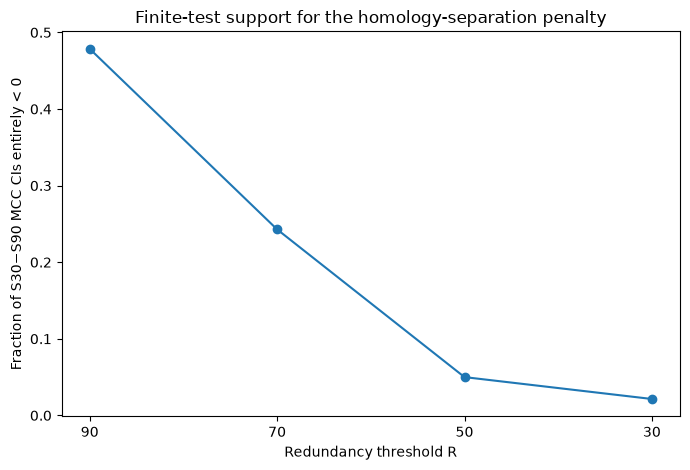

In [23]:
fig, ax = plt.subplots(figsize=(7.0, 4.8))

order = [90, 70, 50, 30]
g = (
    s_uncertainty_by_R
    .set_index("R")
    .reindex(order)
    .reset_index()
)

ax.plot(
    g["R"].astype(str),
    g["fraction_resolved_negative"],
    marker="o",
)
ax.set_xlabel("Redundancy threshold R")
ax.set_ylabel(
    "Fraction of S30−S90 MCC CIs entirely < 0"
)
ax.set_title(
    "Finite-test support for the homology-separation penalty"
)
plt.tight_layout()
plt.show()


The most important RQ17 confirmation of RQ16 would be a progressive decline in the fraction of **directionally resolved negative** S effects from R90 toward R30.

That would show that the attenuation pattern is visible not only in median common-test deltas, but also in their finite-test uncertainty.


# 18. Secondary common-R uncertainty at T30


In [24]:
r_mcc = common_r_boot[
    common_r_boot["metric"].eq("mcc")
].copy()

r_uncertainty_by_S = (
    r_mcc.groupby("S")
    .agg(
        n=("contrast_id", "nunique"),
        median_point_delta=("point_delta", "median"),
        median_ci_width=("ci_width", "median"),
        fraction_resolved_negative=(
            "ci_relation",
            lambda x: (x == "negative").mean(),
        ),
        fraction_resolved_positive=(
            "ci_relation",
            lambda x: (x == "positive").mean(),
        ),
        fraction_overlaps_zero=(
            "ci_relation",
            lambda x: (x == "overlaps_zero").mean(),
        ),
        median_n_common=("n_common", "median"),
        median_min_class_support=(
            "min_class_count", "median"
        ),
    )
    .reset_index()
)

display(r_uncertainty_by_S)


,S,n,median_point_delta,median_ci_width,fraction_resolved_negative,fraction_resolved_positive,fraction_overlaps_zero,median_n_common,median_min_class_support
0,30,35,0.003851,0.083047,0.000000,0.0,0.857143,720.0,70.0
1,50,35,-0.004426,0.067682,0.028571,0.0,0.942857,713.0,81.0
2,70,35,-0.001325,0.069216,0.028571,0.0,0.971429,734.0,59.0
3,90,35,-0.013429,0.079000,0.200000,0.0,0.800000,744.0,54.0


This remains a secondary sensitivity analysis.

RQ16 showed that R changes the biological/evidence universe itself, so same-entity common-R bootstrap intervals should not replace native R effects.


# 19. PU method uncertainty by representation


In [25]:
pu_method_summary = (
    pu_method_boot.groupby(
        ["contrast", "representation_A"]
    )
    .agg(
        n=("contrast_id", "nunique"),
        median_point_delta=("point_delta", "median"),
        median_ci_width=("ci_width", "median"),
        fraction_resolved_positive=(
            "ci_relation",
            lambda x: (x == "positive").mean(),
        ),
        fraction_resolved_negative=(
            "ci_relation",
            lambda x: (x == "negative").mean(),
        ),
        fraction_overlaps_zero=(
            "ci_relation",
            lambda x: (x == "overlaps_zero").mean(),
        ),
        median_directional_consistency=(
            "directional_consistency", "median"
        ),
        median_n_P=("n_P", "median"),
        median_n_U=("n_U", "median"),
    )
    .reset_index()
    .rename(
        columns={
            "representation_A": "representation"
        }
    )
)

display(pu_method_summary)


,contrast,representation,n,median_point_delta,median_ci_width,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero,median_directional_consistency,median_n_P,median_n_U
0,BaggingPU_minus_naive,esm2_t30_150m,64,0.000344,0.017150,0.171875,0.125000,0.703125,0.9080,846.5,38818.5
1,BaggingPU_minus_naive,esm2_t6_8m,64,-0.002757,0.022286,0.062500,0.187500,0.750000,0.8170,846.5,38818.5
2,BaggingPU_minus_naive,onehot_1024,64,0.093082,0.060287,0.593750,0.031250,0.375000,1.0000,846.5,38818.5
3,BaggingPU_minus_naive,roxy_48,64,0.000000,0.020514,0.031250,0.015625,0.953125,0.7025,846.5,38818.5
4,EN_minus_naive,esm2_t30_150m,64,0.000000,0.000000,0.000000,0.000000,1.000000,0.0000,846.5,38818.5
5,EN_minus_naive,esm2_t6_8m,64,0.000000,0.000000,0.000000,0.000000,1.000000,0.0000,846.5,38818.5
6,EN_minus_naive,onehot_1024,64,0.000000,0.000000,0.343750,0.000000,0.656250,0.0000,846.5,38818.5
7,EN_minus_naive,roxy_48,64,0.000000,0.000000,0.250000,0.000000,0.750000,0.0000,846.5,38818.5


This is where RQ15's representation-specific PU behavior receives uncertainty support.

In particular:

- one-hot BaggingPU gains should be inspected for directional resolution;
- Roxy/T6/T30 BaggingPU contrasts are expected to overlap zero much more frequently;
- Elkan–Noto remains interpreted at U95, avoiding its U99 clipping artifact.


# 20. PU representation uncertainty — T30 versus T6


In [26]:
pu_rep_summary = (
    pu_rep_boot.groupby("method_A")
    .agg(
        n=("contrast_id", "nunique"),
        median_point_delta=("point_delta", "median"),
        median_ci_width=("ci_width", "median"),
        fraction_resolved_positive=(
            "ci_relation",
            lambda x: (x == "positive").mean(),
        ),
        fraction_resolved_negative=(
            "ci_relation",
            lambda x: (x == "negative").mean(),
        ),
        fraction_overlaps_zero=(
            "ci_relation",
            lambda x: (x == "overlaps_zero").mean(),
        ),
        median_directional_consistency=(
            "directional_consistency", "median"
        ),
    )
    .reset_index()
    .rename(columns={"method_A": "method"})
)

display(pu_rep_summary)


,method,n,median_point_delta,median_ci_width,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero,median_directional_consistency
0,baggingpu,64,0.075929,0.042323,1.0,0.0,0.0,1.0
1,elkan_noto,64,0.072383,0.043146,1.0,0.0,0.0,1.0
2,naive,64,0.072383,0.041958,1.0,0.0,0.0,1.0


If T30−T6 remains positive under naive, BaggingPU and Elkan–Noto with similar uncertainty behavior, it reinforces RQ15's conclusion that the representation advantage is largely separable from the PU paradigm for known-positive recovery.


# 21. VAL Low-N finite-test uncertainty


,R,S,metric,n,median_point_value,median_ci_width,median_n_positive,min_n_positive,max_n_positive
0,30,30,ap_skill,5,0.827756,0.297850,17.0,17,17
1,30,30,mcc,5,0.776480,0.297473,17.0,17,17
2,30,30,recall,5,0.705882,0.411765,17.0,17,17
3,30,90,ap_skill,5,0.832076,0.280802,17.0,17,17
4,30,90,mcc,5,0.768893,0.308371,17.0,17,17
5,30,90,recall,5,0.647059,0.411765,17.0,17,17
6,90,30,ap_skill,5,0.763971,0.391443,14.0,14,14
7,90,30,mcc,5,0.706805,0.330237,14.0,14,14
8,90,30,recall,5,0.571429,0.500000,14.0,14,14
9,90,90,ap_skill,5,0.911047,0.192967,26.0,26,26


Spearman(n_positive, MCC CI width) = -0.7112416338025603


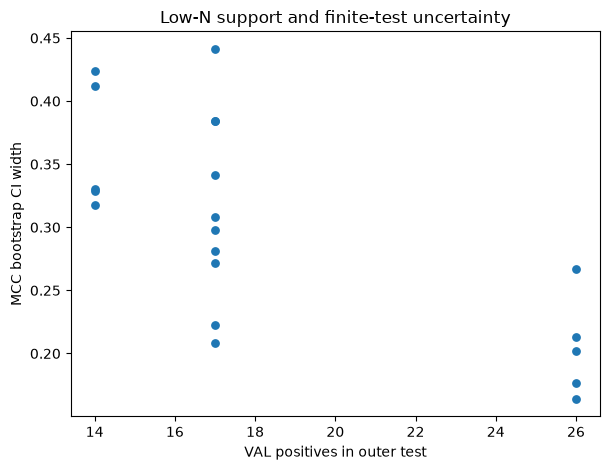

In [27]:
val_summary = (
    val_uncertainty.groupby(
        ["R", "S", "metric"]
    )
    .agg(
        n=("contrast_id", "nunique"),
        median_point_value=("point_value", "median"),
        median_ci_width=("ci_width", "median"),
        median_n_positive=("n_positive", "median"),
        min_n_positive=("n_positive", "min"),
        max_n_positive=("n_positive", "max"),
    )
    .reset_index()
)

display(val_summary)

val_mcc = val_uncertainty[
    val_uncertainty["metric"].eq("mcc")
].copy()

if len(val_mcc):
    print(
        "Spearman(n_positive, MCC CI width) =",
        val_mcc["n_positive"].corr(
            val_mcc["ci_width"],
            method="spearman",
        ),
    )

    fig, ax = plt.subplots(figsize=(6.2, 4.8))
    ax.scatter(
        val_mcc["n_positive"],
        val_mcc["ci_width"],
        s=28,
    )
    ax.set_xlabel("VAL positives in outer test")
    ax.set_ylabel("MCC bootstrap CI width")
    ax.set_title("Low-N support and finite-test uncertainty")
    plt.tight_layout()
    plt.show()


The VAL bootstrap distributions are expected to be relatively discrete because the positive class contains only a few dozen proteins.

This is not a defect of the bootstrap. It is the uncertainty consequence of the evidence-limited regime documented in RQ10.


# 22. Cross-family uncertainty comparison


In [28]:
uncertainty_family_rows = []

for name, frame in [
    (
        "T30_minus_T6_supervised",
        supervised_pair_boot[
            supervised_pair_boot["contrast"].eq(
                "T30_minus_T6"
            )
            & supervised_pair_boot["metric"].eq("mcc")
        ],
    ),
    (
        "T30_minus_Roxy_supervised",
        supervised_pair_boot[
            supervised_pair_boot["contrast"].eq(
                "T30_minus_Roxy"
            )
            & supervised_pair_boot["metric"].eq("mcc")
        ],
    ),
    (
        "MLP_minus_LR_T30",
        supervised_pair_boot[
            supervised_pair_boot["contrast"].eq(
                "MLP_minus_LR"
            )
            & supervised_pair_boot["metric"].eq("mcc")
        ],
    ),
    (
        "MLP_minus_XGB_T30",
        supervised_pair_boot[
            supervised_pair_boot["contrast"].eq(
                "MLP_minus_XGB"
            )
            & supervised_pair_boot["metric"].eq("mcc")
        ],
    ),
    (
        "Common_S30_minus_S90",
        common_s_boot[
            common_s_boot["metric"].eq("mcc")
        ],
    ),
    (
        "Common_R30_minus_R90_T30",
        common_r_boot[
            common_r_boot["metric"].eq("mcc")
        ],
    ),
    (
        "PU_Bagging_minus_naive",
        pu_method_boot[
            pu_method_boot["contrast"].eq(
                "BaggingPU_minus_naive"
            )
        ],
    ),
    (
        "PU_EN_minus_naive",
        pu_method_boot[
            pu_method_boot["contrast"].eq(
                "EN_minus_naive"
            )
        ],
    ),
    (
        "PU_T30_minus_T6",
        pu_rep_boot,
    ),
]:
    if len(frame) == 0:
        continue

    uncertainty_family_rows.append({
        "family": name,
        "n_contrasts": frame["contrast_id"].nunique(),
        "median_abs_point_delta": (
            frame["point_delta"].abs().median()
        ),
        "median_ci_width": frame["ci_width"].median(),
        "fraction_resolved_positive": (
            frame["ci_relation"].eq("positive").mean()
        ),
        "fraction_resolved_negative": (
            frame["ci_relation"].eq("negative").mean()
        ),
        "fraction_overlaps_zero": (
            frame["ci_relation"].eq(
                "overlaps_zero"
            ).mean()
        ),
        "median_directional_consistency": (
            frame["directional_consistency"].median()
        ),
    })

uncertainty_family_summary = pd.DataFrame(
    uncertainty_family_rows
)

display(uncertainty_family_summary)


,family,n_contrasts,median_abs_point_delta,median_ci_width,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero,median_directional_consistency
0,T30_minus_T6_supervised,140,0.069355,0.060056,0.585714,0.000000,0.414286,0.9980
1,T30_minus_Roxy_supervised,140,0.213812,0.081427,0.950000,0.000000,0.042857,1.0000
2,MLP_minus_LR_T30,28,0.034639,0.051922,0.571429,0.000000,0.428571,0.9985
3,MLP_minus_XGB_T30,28,0.006139,0.035750,0.107143,0.000000,0.892857,0.8495
4,Common_S30_minus_S90,560,0.020275,0.074881,0.019643,0.198214,0.728571,0.8395
5,Common_R30_minus_R90_T30,140,0.012044,0.073386,0.000000,0.064286,0.892857,0.6650
6,PU_Bagging_minus_naive,256,0.007299,0.025291,0.214844,0.089844,0.695312,0.8675
7,PU_EN_minus_naive,256,0.000000,0.000000,0.148438,0.000000,0.851562,0.0000
8,PU_T30_minus_T6,192,0.073611,0.042738,1.000000,0.000000,0.000000,1.0000


# 23. RQ17 evidence synthesis


In [29]:
rq17_evidence = {
    "supervised_representation": representation_uncertainty,
    "supervised_algorithm": algorithm_uncertainty,
    "common_S_by_R": s_uncertainty_by_R,
    "common_S_by_task_R": s_uncertainty_by_task_R,
    "common_R_by_S": r_uncertainty_by_S,
    "PU_method_by_representation": pu_method_summary,
    "PU_T30_vs_T6": pu_rep_summary,
    "VAL": val_summary,
    "cross_family": uncertainty_family_summary,
}

for name, frame in rq17_evidence.items():
    print("\n---", name, "---")
    display(frame)



--- supervised_representation ---


,contrast,task,n,median_point_delta,median_ci_width,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero,median_directional_consistency
0,T30_minus_Roxy,global_easy,20,0.241233,0.057873,1.00,0.0,0.00,1.0000
1,T30_minus_Roxy,global_hard,20,0.071575,0.061518,1.00,0.0,0.00,1.0000
2,T30_minus_Roxy,global_mixed,20,0.243117,0.052462,1.00,0.0,0.00,1.0000
3,T30_minus_Roxy,multiclass_clean,20,0.085630,0.087077,1.00,0.0,0.00,1.0000
4,T30_minus_Roxy,subtype_depolymerase,20,0.090958,0.092181,0.90,0.0,0.10,1.0000
5,T30_minus_Roxy,subtype_endolysin,20,0.312720,0.064197,1.00,0.0,0.00,1.0000
6,T30_minus_Roxy,subtype_val,20,0.409643,0.376962,0.75,0.0,0.20,1.0000
7,T30_minus_T6,global_easy,20,0.110030,0.043656,1.00,0.0,0.00,1.0000
8,T30_minus_T6,global_hard,20,0.005935,0.037352,0.05,0.0,0.95,0.7880
9,T30_minus_T6,global_mixed,20,0.100210,0.042142,1.00,0.0,0.00,1.0000



--- supervised_algorithm ---


,contrast,task,n,median_point_delta,median_ci_width,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero
0,MLP_minus_LR,global_easy,4,0.034158,0.030249,1.00,0.0,0.00
1,MLP_minus_LR,global_hard,4,0.003837,0.024335,0.00,0.0,1.00
2,MLP_minus_LR,global_mixed,4,0.038720,0.030755,1.00,0.0,0.00
3,MLP_minus_LR,multiclass_clean,4,0.025280,0.070395,0.25,0.0,0.75
4,MLP_minus_LR,subtype_depolymerase,4,0.041942,0.069092,0.75,0.0,0.25
5,MLP_minus_LR,subtype_endolysin,4,0.052234,0.037533,1.00,0.0,0.00
6,MLP_minus_LR,subtype_val,4,-0.026914,0.268824,0.00,0.0,1.00
7,MLP_minus_XGB,global_easy,4,0.004183,0.022935,0.00,0.0,1.00
8,MLP_minus_XGB,global_hard,4,-0.000668,0.025254,0.00,0.0,1.00
9,MLP_minus_XGB,global_mixed,4,0.006924,0.023043,0.25,0.0,0.75



--- common_S_by_R ---


,R,n,median_point_delta,median_ci_width,fraction_resolved_negative,fraction_resolved_positive,fraction_overlaps_zero,median_directional_consistency,median_n_common,median_min_class_support
0,30,140,0.000000,0.081335,0.021429,0.057143,0.885714,0.694000,797.0,75.0
1,50,140,-0.007269,0.069884,0.050000,0.007143,0.857143,0.722701,1242.0,97.0
2,70,140,-0.020030,0.084429,0.242857,0.014286,0.700000,0.884500,1810.0,124.0
3,90,140,-0.039151,0.063817,0.478571,0.000000,0.471429,0.976000,2490.0,157.0


... (8 outputs left out)


--- VAL ---


,R,S,metric,n,median_point_value,median_ci_width,median_n_positive,min_n_positive,max_n_positive
0,30,30,ap_skill,5,0.827756,0.297850,17.0,17,17
1,30,30,mcc,5,0.776480,0.297473,17.0,17,17
2,30,30,recall,5,0.705882,0.411765,17.0,17,17
3,30,90,ap_skill,5,0.832076,0.280802,17.0,17,17
4,30,90,mcc,5,0.768893,0.308371,17.0,17,17
5,30,90,recall,5,0.647059,0.411765,17.0,17,17
6,90,30,ap_skill,5,0.763971,0.391443,14.0,14,14
7,90,30,mcc,5,0.706805,0.330237,14.0,14,14
8,90,30,recall,5,0.571429,0.500000,14.0,14,14
9,90,90,ap_skill,5,0.911047,0.192967,26.0,26,26



--- cross_family ---


,family,n_contrasts,median_abs_point_delta,median_ci_width,fraction_resolved_positive,fraction_resolved_negative,fraction_overlaps_zero,median_directional_consistency
0,T30_minus_T6_supervised,140,0.069355,0.060056,0.585714,0.000000,0.414286,0.9980
1,T30_minus_Roxy_supervised,140,0.213812,0.081427,0.950000,0.000000,0.042857,1.0000
2,MLP_minus_LR_T30,28,0.034639,0.051922,0.571429,0.000000,0.428571,0.9985
3,MLP_minus_XGB_T30,28,0.006139,0.035750,0.107143,0.000000,0.892857,0.8495
4,Common_S30_minus_S90,560,0.020275,0.074881,0.019643,0.198214,0.728571,0.8395
5,Common_R30_minus_R90_T30,140,0.012044,0.073386,0.000000,0.064286,0.892857,0.6650
6,PU_Bagging_minus_naive,256,0.007299,0.025291,0.214844,0.089844,0.695312,0.8675
7,PU_EN_minus_naive,256,0.000000,0.000000,0.148438,0.000000,0.851562,0.0000
8,PU_T30_minus_T6,192,0.073611,0.042738,1.000000,0.000000,0.000000,1.0000


## RQ17 synthesis questions

After execution, RQ17 should answer:

1. How often is `T30−T6` directionally positive after paired finite-test bootstrap?
2. Is `T30−Roxy` more consistently resolved than `T30−T6`?
3. Do representation effects remain stronger/more resolved than algorithm effects?
4. Does `MLP−XGB` frequently overlap zero, consistent with the upper-tier interpretation from RQ8?
5. Does the common-test `S30−S90` penalty have CIs below zero primarily at R90/R70 and lose directional resolution toward R30?
6. Does AP-skill support the same supervised representation/common-S conclusions as MCC?
7. Are common-R intervals comparatively small/uncertain, consistent with RQ16's finding that most native R magnitude comes from evidence/population restructuring?
8. Is one-hot the representation where BaggingPU−naive U95 gains are most often directionally resolved?
9. Do BaggingPU gains under T30/T6 mostly overlap zero for known-positive recovery?
10. Does Elkan–Noto remain unresolved relative to naive at U95 across most cells?
11. Does `T30−T6` PU recovery remain directionally positive under all three paradigms?
12. How wide are VAL MCC/recall/AP-skill intervals at 14–32 positives?
13. Does VAL interval width decrease as positive support rises?
14. Which principal claims are strongly resolved, which are directional but uncertain, and which should remain descriptive?
15. Are any RQ1–RQ16 conclusions contradicted by finite-test uncertainty strongly enough to require qualification?

RQ17 should make the manuscript **more conservative where needed**, not manufacture significance.


## Manuscript-level interpretation targets

If representation contrasts are broadly resolved:

> **The advantage of pretrained protein representations is not only large in point estimates but remains directionally consistent under paired finite-test resampling, particularly for T30 relative to simpler representations.**

If algorithm contrasts frequently overlap zero:

> **Differences among competitive downstream learners are often small relative to finite-test uncertainty, reinforcing that representation choice contributes more strongly to predictive behavior than classifier identity.**

If common-S negative intervals decline from R90 to R30:

> **Finite-test uncertainty reproduces the attenuation of homology-separation penalties under stringent redundancy control, strengthening the evidence that the two evaluation axes are not independent.**

For PU:

> **Dedicated PU learning shows representation-specific uncertainty: BaggingPU can provide a resolved recovery advantage in selected feature spaces while remaining indistinguishable from naive P-vs-U in others.**

For VAL:

> **Low-support VAL evaluation produces wide and discrete finite-test uncertainty, confirming that evidence scarcity limits not only learning but the precision with which model differences can be measured.**


# 24. Export final RQ17 summaries


In [30]:
FINAL_EXPORTS = {
    RQ17_CACHE / "rq17_supervised_representation_uncertainty_summary.tsv":
        representation_uncertainty,
    RQ17_CACHE / "rq17_supervised_algorithm_uncertainty_summary.tsv":
        algorithm_uncertainty,
    RQ17_CACHE / "rq17_commonS_uncertainty_by_R.tsv":
        s_uncertainty_by_R,
    RQ17_CACHE / "rq17_commonS_uncertainty_by_task_R.tsv":
        s_uncertainty_by_task_R,
    RQ17_CACHE / "rq17_commonR_T30_uncertainty_by_S.tsv":
        r_uncertainty_by_S,
    RQ17_CACHE / "rq17_PU_method_uncertainty_by_representation.tsv":
        pu_method_summary,
    RQ17_CACHE / "rq17_PU_T30_T6_uncertainty_summary.tsv":
        pu_rep_summary,
    RQ17_CACHE / "rq17_VAL_uncertainty_summary.tsv":
        val_summary,
    RQ17_CACHE / "rq17_cross_family_uncertainty_summary.tsv":
        uncertainty_family_summary,
}

for path, frame in FINAL_EXPORTS.items():
    frame.to_csv(
        path,
        sep="\t",
        index=False,
    )

print("Saved RQ17 final summaries:")
for path in FINAL_EXPORTS:
    print(" ", path)


Saved RQ17 final summaries:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_bootstrap/rq17/rq17_supervised_representation_uncertainty_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_bootstrap/rq17/rq17_supervised_algorithm_uncertainty_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_bootstrap/rq17/rq17_commonS_uncertainty_by_R.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_bootstrap/rq17/rq17_commonS_uncertainty_by_task_R.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_bootstrap/rq17/rq17_commonR_T30_uncertainty_by_S.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_bootstrap/rq17/rq17_PU_method_uncertainty_by_representation.tsv
  /home/david/Desktop/colabs/inta_p

## Final guardrails before freezing RQ17

- Use the default 1,000 replicates for manuscript results.
- Do not interpret these intervals as training-seed uncertainty.
- Do not call an overlapping-zero interval “equivalent”.
- Do not generate a p-value hierarchy from bootstrap sign fractions.
- Keep the observed effect size visible even when its CI overlaps zero.
- For VAL, always report positive support next to CI width.
- Common-S/R bootstrap results apply to shared-entity sensitivity subsets, not the full native benchmark population.
- Native R effects remain the effect of the complete redundancy-control protocol.
- Elkan–Noto is bootstrapped at U95; U99 remains unsuitable for comparative interpretation because of clipping/ties.
- Candidate-ranking uncertainty is not bootstrapped here; RQ12–RQ15 already characterize ranking disagreement and RQ17 focuses on principal metric effects.
- If a claim does not survive finite-test uncertainty, qualify the claim rather than adding more tests.
